# H&M Customer Segmentation — Phase 8
## Marketing Decision Support

## Mục tiêu

Phase 8 chuyển segmentation thành **hệ thống hỗ trợ quyết định marketing**, không tuyên bố hành động nào là tối ưu về mặt nhân quả.

Kiến trúc:

\[
Customer\ Features \rightarrow Segment \rightarrow Business\ Diagnosis
\rightarrow Marketing\ Objective \rightarrow Action\ Family
\]

sau đó:

\[
Segment\ Strategy + Individual\ Customer\ Context
\rightarrow Personalized\ Decision\ Support
\]

H&M không có campaign exposure, coupon assignment, email/open/click hay A/B treatment, nên recommendation ở đây là **decision support**, không phải causal optimal policy.

## 0. Input / Output

Input:

```text
data/processed/
├── transactions_clean.parquet
├── articles_clean.parquet

data/features/
└── customer_features_master.parquet

data/results/
└── customer_segment_assignments.parquet

reports/tables/phase7_cluster_profiling/
├── 11_proposed_segment_names.csv
├── 12_segment_naming_evidence.csv
├── 15_business_segment_summary.csv
└── 16_segment_interpretability_check.csv
```

Output:

```text
data/results/
├── segment_marketing_strategy.csv
├── segment_fashion_preferences.csv
└── customer_marketing_decision_support.parquet

reports/tables/phase8_marketing_decision_support/
reports/figures/phase8_marketing_decision_support/
```

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 240)
pd.set_option("display.width", 260)

ROOT = Path("..")
PROCESSED_DIR = ROOT / "data" / "processed"
FEATURE_DIR = ROOT / "data" / "features"
RESULT_DIR = ROOT / "data" / "results"
PHASE7_TABLE_DIR = ROOT / "reports" / "tables" / "phase7_cluster_profiling"
FIG_DIR = ROOT / "reports" / "figures" / "phase8_marketing_decision_support"
TABLE_DIR = ROOT / "reports" / "tables" / "phase8_marketing_decision_support"

for d in [RESULT_DIR, FIG_DIR, TABLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TX_PATH = PROCESSED_DIR / "transactions_clean.parquet"
ARTICLES_PATH = PROCESSED_DIR / "articles_clean.parquet"
MASTER_PATH = FEATURE_DIR / "customer_features_master.parquet"
SEGMENT_ASSIGN_PATH = RESULT_DIR / "customer_segment_assignments.parquet"

SEGMENT_NAMES_PATH = PHASE7_TABLE_DIR / "11_proposed_segment_names.csv"
BUSINESS_SUMMARY_PATH = PHASE7_TABLE_DIR / "15_business_segment_summary.csv"
INTERPRETABILITY_PATH = PHASE7_TABLE_DIR / "16_segment_interpretability_check.csv"

required = [
    TX_PATH, ARTICLES_PATH, MASTER_PATH, SEGMENT_ASSIGN_PATH,
    SEGMENT_NAMES_PATH, BUSINESS_SUMMARY_PATH, INTERPRETABILITY_PATH
]

for p in required:
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")

..\data\processed\transactions_clean.parquet: OK
..\data\processed\articles_clean.parquet: OK
..\data\features\customer_features_master.parquet: OK
..\data\results\customer_segment_assignments.parquet: OK
..\reports\tables\phase7_cluster_profiling\11_proposed_segment_names.csv: OK
..\reports\tables\phase7_cluster_profiling\15_business_segment_summary.csv: OK
..\reports\tables\phase7_cluster_profiling\16_segment_interpretability_check.csv: OK


# A. Load Phase 7 Results

Marketing logic dựa vào **segment/profile**, không dựa vào `cluster_id`.

Sai:
```text
cluster 2 → send coupon
```

Đúng:
```text
High-Value At-Risk → reactivation objective
```

In [2]:
segments = pd.read_parquet(SEGMENT_ASSIGN_PATH)
master = pd.read_parquet(MASTER_PATH)
segment_names = pd.read_csv(SEGMENT_NAMES_PATH)
business_summary = pd.read_csv(BUSINESS_SUMMARY_PATH)
interpretability = pd.read_csv(INTERPRETABILITY_PATH)

assert segments["customer_id"].duplicated().sum() == 0
assert segments["proposed_segment_name"].isna().sum() == 0

display(segment_names)
display(business_summary)

,cluster_id,base_segment_name,segment_descriptor,duplicate_name_flag,proposed_segment_name
0,0,Dormant Low-Value,No strong extended descriptor,False,Dormant Low-Value
1,1,High-Value Loyal,Broad Fashion Interest,False,High-Value Loyal
2,2,Active Developing,No strong extended descriptor,False,Active Developing
3,3,Frequent Core,Broad Fashion Interest,False,Frequent Core


,cluster_id,customers,total_observed_spend,median_observed_spend,pct_customers,pct_observed_spend,spend_share_index,base_segment_name,segment_descriptor,duplicate_name_flag,proposed_segment_name
0,0,383758,55595.871712,0.093186,28.170253,6.284533,0.223091,Dormant Low-Value,Core segment,False,Dormant Low-Value
1,1,138928,445659.926458,2.522153,10.198190,50.377206,4.939819,High-Value Loyal,Broad Fashion Interest,False,High-Value Loyal
2,2,560287,122323.589492,0.171034,41.128592,13.827406,0.336199,Active Developing,Slow Repeat Cycle,False,Active Developing
3,3,279308,261066.586390,0.855898,20.502965,29.510855,1.439346,Frequent Core,Broad Fashion Interest,False,Frequent Core


# B. Segment-Level Strategy Library

Các action chỉ mô tả **nhóm chiến lược nên thử**, không quy định mức giảm giá hay ngân sách tối ưu.

In [3]:
STRATEGY_LIBRARY = {
    "High-Value Loyal": {
        "business_diagnosis": "Active customers with strong historical frequency and value.",
        "marketing_objective": "Retention and value protection",
        "primary_action_family": "Loyalty / exclusivity / early-access engagement",
        "secondary_action_family": "Cross-sell into adjacent fashion categories",
        "message_direction": "Recognition, exclusivity, relevance; avoid unnecessary blanket discounting.",
        "primary_kpi": "Repeat purchase rate / retention rate",
        "secondary_kpi": "Category breadth / spend per active customer",
        "risk_note": "Over-discounting high-value customers can destroy margin without incremental behavior."
    },
    "High-Value At-Risk": {
        "business_diagnosis": "Historically valuable customers whose purchase activity has become less recent.",
        "marketing_objective": "Reactivation",
        "primary_action_family": "Personalized win-back / category reminder",
        "secondary_action_family": "Test targeted incentive only if needed",
        "message_direction": "Lead with previously relevant fashion categories and newness before price.",
        "primary_kpi": "Reactivation rate",
        "secondary_kpi": "Days to next purchase / recovered spend",
        "risk_note": "Do not assume inactivity means churn; browsing/campaign data are unavailable."
    },
    "Recent / New Buyers": {
        "business_diagnosis": "Recently active customers with limited historical purchase frequency.",
        "marketing_objective": "Second-purchase activation",
        "primary_action_family": "Post-purchase onboarding / complementary-category recommendation",
        "secondary_action_family": "New-arrival discovery",
        "message_direction": "Reduce choice friction and extend the first purchase into a second relevant purchase.",
        "primary_kpi": "Second-purchase conversion",
        "secondary_kpi": "Days from first to second purchase",
        "risk_note": "Limited history makes personalization uncertain."
    },
    "Dormant Low-Value": {
        "business_diagnosis": "Low historical value/frequency with low recent activity.",
        "marketing_objective": "Low-cost re-engagement or deprioritization",
        "primary_action_family": "Low-cost broad re-engagement",
        "secondary_action_family": "Experimental value proposition",
        "message_direction": "Use low-cost channels before expensive incentives.",
        "primary_kpi": "Reactivation rate",
        "secondary_kpi": "Incremental revenue per contacted customer",
        "risk_note": "Avoid high spend on a low-response segment without uplift evidence."
    },
    "Frequent Core": {
        "business_diagnosis": "Strong purchase frequency but not yet exceptional monetary value.",
        "marketing_objective": "Value expansion",
        "primary_action_family": "Cross-sell / basket expansion",
        "secondary_action_family": "Premium-category discovery",
        "message_direction": "Build on existing shopping habit with adjacent categories.",
        "primary_kpi": "Spend per purchase day",
        "secondary_kpi": "Category breadth / average item price",
        "risk_note": "Do not push premium products when price behavior indicates lower-price preference."
    },
    "High-Spend Occasional": {
        "business_diagnosis": "High historical spending with lower purchase frequency.",
        "marketing_objective": "Frequency growth",
        "primary_action_family": "Purchase-cycle reminder / relevant newness",
        "secondary_action_family": "High-value category reinforcement",
        "message_direction": "Use purchase cadence and preferred categories to create reasons to return.",
        "primary_kpi": "Purchase days per customer",
        "secondary_kpi": "Time to next purchase",
        "risk_note": "High spend may reflect a few large purchases rather than loyalty."
    },
    "Active Developing": {
        "business_diagnosis": "Currently active customers who have not yet reached strong frequency/value levels.",
        "marketing_objective": "Nurture and progression",
        "primary_action_family": "Relevant product/category discovery",
        "secondary_action_family": "Cross-sell / repeat-purchase activation",
        "message_direction": "Use known fashion preferences without aggressive promotion.",
        "primary_kpi": "Repeat purchase rate",
        "secondary_kpi": "Frequency / category breadth growth",
        "risk_note": "This is a transitional segment and should be re-evaluated over time."
    },
    "Regular / Transitional": {
        "business_diagnosis": "Customers with mixed or moderate behavioral signals.",
        "marketing_objective": "Learn and differentiate",
        "primary_action_family": "Preference discovery / controlled experimentation",
        "secondary_action_family": "General relevant newness",
        "message_direction": "Collect more evidence before expensive or highly specific targeting.",
        "primary_kpi": "Repeat purchase / response proxy",
        "secondary_kpi": "Movement toward interpretable high-value or active segments",
        "risk_note": "Mixed profiles should not receive highly prescriptive treatment."
    }
}

strategy_library_df = pd.DataFrame.from_dict(
    STRATEGY_LIBRARY,
    orient="index"
).reset_index(names="base_segment_name")

display(strategy_library_df)

,base_segment_name,business_diagnosis,marketing_objective,primary_action_family,secondary_action_family,message_direction,primary_kpi,secondary_kpi,risk_note
0,High-Value Loyal,Active customers with strong historical freque...,Retention and value protection,Loyalty / exclusivity / early-access engagement,Cross-sell into adjacent fashion categories,"Recognition, exclusivity, relevance; avoid unn...",Repeat purchase rate / retention rate,Category breadth / spend per active customer,Over-discounting high-value customers can dest...
1,High-Value At-Risk,Historically valuable customers whose purchase...,Reactivation,Personalized win-back / category reminder,Test targeted incentive only if needed,Lead with previously relevant fashion categori...,Reactivation rate,Days to next purchase / recovered spend,Do not assume inactivity means churn; browsing...
2,Recent / New Buyers,Recently active customers with limited histori...,Second-purchase activation,Post-purchase onboarding / complementary-categ...,New-arrival discovery,Reduce choice friction and extend the first pu...,Second-purchase conversion,Days from first to second purchase,Limited history makes personalization uncertain.
3,Dormant Low-Value,Low historical value/frequency with low recent...,Low-cost re-engagement or deprioritization,Low-cost broad re-engagement,Experimental value proposition,Use low-cost channels before expensive incenti...,Reactivation rate,Incremental revenue per contacted customer,Avoid high spend on a low-response segment wit...
4,Frequent Core,Strong purchase frequency but not yet exceptio...,Value expansion,Cross-sell / basket expansion,Premium-category discovery,Build on existing shopping habit with adjacent...,Spend per purchase day,Category breadth / average item price,Do not push premium products when price behavi...
5,High-Spend Occasional,High historical spending with lower purchase f...,Frequency growth,Purchase-cycle reminder / relevant newness,High-value category reinforcement,Use purchase cadence and preferred categories ...,Purchase days per customer,Time to next purchase,High spend may reflect a few large purchases r...
6,Active Developing,Currently active customers who have not yet re...,Nurture and progression,Relevant product/category discovery,Cross-sell / repeat-purchase activation,Use known fashion preferences without aggressi...,Repeat purchase rate,Frequency / category breadth growth,This is a transitional segment and should be r...
7,Regular / Transitional,Customers with mixed or moderate behavioral si...,Learn and differentiate,Preference discovery / controlled experimentation,General relevant newness,Collect more evidence before expensive or high...,Repeat purchase / response proxy,Movement toward interpretable high-value or ac...,Mixed profiles should not receive highly presc...


In [4]:
segment_strategy = (
    segment_names[[
        "cluster_id",
        "base_segment_name",
        "proposed_segment_name",
        "segment_descriptor",
        "duplicate_name_flag"
    ]]
    .merge(strategy_library_df, on="base_segment_name", how="left")
    .merge(
        interpretability[["cluster_id", "interpretable_for_phase8"]],
        on="cluster_id",
        how="left"
    )
)

fallback = segment_strategy["marketing_objective"].isna()

segment_strategy.loc[fallback, "business_diagnosis"] = "Manual profile review required."
segment_strategy.loc[fallback, "marketing_objective"] = "Learn and differentiate"
segment_strategy.loc[fallback, "primary_action_family"] = "Controlled experimentation"
segment_strategy.loc[fallback, "secondary_action_family"] = "Preference discovery"
segment_strategy.loc[fallback, "message_direction"] = "Use measured preferences; avoid strong assumptions."
segment_strategy.loc[fallback, "primary_kpi"] = "Repeat purchase / response proxy"
segment_strategy.loc[fallback, "secondary_kpi"] = "Segment migration / customer value"
segment_strategy.loc[fallback, "risk_note"] = "No standard strategy mapping exists; manual review required."

display(segment_strategy)

segment_strategy.to_csv(RESULT_DIR / "segment_marketing_strategy.csv", index=False)
segment_strategy.to_csv(TABLE_DIR / "01_segment_marketing_strategy.csv", index=False)

,cluster_id,base_segment_name,proposed_segment_name,segment_descriptor,duplicate_name_flag,business_diagnosis,marketing_objective,primary_action_family,secondary_action_family,message_direction,primary_kpi,secondary_kpi,risk_note,interpretable_for_phase8
0,0,Dormant Low-Value,Dormant Low-Value,No strong extended descriptor,False,Low historical value/frequency with low recent...,Low-cost re-engagement or deprioritization,Low-cost broad re-engagement,Experimental value proposition,Use low-cost channels before expensive incenti...,Reactivation rate,Incremental revenue per contacted customer,Avoid high spend on a low-response segment wit...,True
1,1,High-Value Loyal,High-Value Loyal,Broad Fashion Interest,False,Active customers with strong historical freque...,Retention and value protection,Loyalty / exclusivity / early-access engagement,Cross-sell into adjacent fashion categories,"Recognition, exclusivity, relevance; avoid unn...",Repeat purchase rate / retention rate,Category breadth / spend per active customer,Over-discounting high-value customers can dest...,True
2,2,Active Developing,Active Developing,No strong extended descriptor,False,Currently active customers who have not yet re...,Nurture and progression,Relevant product/category discovery,Cross-sell / repeat-purchase activation,Use known fashion preferences without aggressi...,Repeat purchase rate,Frequency / category breadth growth,This is a transitional segment and should be r...,True
3,3,Frequent Core,Frequent Core,Broad Fashion Interest,False,Strong purchase frequency but not yet exceptio...,Value expansion,Cross-sell / basket expansion,Premium-category discovery,Build on existing shopping habit with adjacent...,Spend per purchase day,Category breadth / average item price,Do not push premium products when price behavi...,True


# C. Segment-Level Fashion Preferences

Nối transaction → segment → article metadata để tìm Top product type / garment group / section của từng segment.

In [5]:
import duckdb
con = duckdb.connect()

articles = pd.read_parquet(ARTICLES_PATH)

con.register(
    "segment_dim",
    segments[["customer_id", "cluster_id", "proposed_segment_name"]]
)

article_cols = ["article_id"] + [
    c for c in [
        "product_type_name",
        "garment_group_name",
        "section_name",
        "department_name",
        "colour_group_name"
    ]
    if c in articles.columns
]

con.register("article_dim", articles[article_cols])
TX = f"read_parquet('{TX_PATH.as_posix()}')"

def segment_top_dimension(dimension, top_n=10):
    return con.execute(f'''
        WITH counts AS (
            SELECT
                s.cluster_id,
                s.proposed_segment_name,
                a.{dimension} AS value,
                COUNT(*) AS transaction_rows,
                COUNT(DISTINCT tx.customer_id) AS customers
            FROM {TX} tx
            INNER JOIN segment_dim s
                ON tx.customer_id = s.customer_id
            LEFT JOIN article_dim a
                ON tx.article_id = a.article_id
            WHERE a.{dimension} IS NOT NULL
            GROUP BY 1,2,3
        ),
        ranked AS (
            SELECT *,
                   ROW_NUMBER() OVER (
                       PARTITION BY cluster_id
                       ORDER BY transaction_rows DESC
                   ) AS rank_in_segment
            FROM counts
        )
        SELECT *
        FROM ranked
        WHERE rank_in_segment <= {top_n}
        ORDER BY cluster_id, rank_in_segment
    ''').df()

tables = []
for dim in ["product_type_name", "garment_group_name", "section_name"]:
    if dim in article_cols:
        t = segment_top_dimension(dim)
        t["dimension"] = dim
        tables.append(t)

segment_preferences = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
display(segment_preferences.head(30))

segment_preferences.to_csv(RESULT_DIR / "segment_fashion_preferences.csv", index=False)
segment_preferences.to_csv(TABLE_DIR / "02_segment_fashion_preferences.csv", index=False)

,cluster_id,proposed_segment_name,value,transaction_rows,customers,rank_in_segment,dimension
0,0,Dormant Low-Value,Trousers,295098,130133,1,product_type_name
1,0,Dormant Low-Value,Sweater,210678,105717,2,product_type_name
2,0,Dormant Low-Value,Dress,167450,80683,3,product_type_name
3,0,Dormant Low-Value,T-shirt,161135,75741,4,product_type_name
4,0,Dormant Low-Value,Top,90194,56260,5,product_type_name
5,0,Dormant Low-Value,Blouse,88136,51540,6,product_type_name
6,0,Dormant Low-Value,Vest top,86535,44079,7,product_type_name
7,0,Dormant Low-Value,Swimwear bottom,77347,35773,8,product_type_name
8,0,Dormant Low-Value,Bikini top,76510,34840,9,product_type_name
9,0,Dormant Low-Value,Bra,73182,38050,10,product_type_name


# D. Customer Context Engine

Hàm lấy:
- first/last purchase;
- purchase days;
- observed spend;
- avg item price;
- preferred channel;
- favorite product type;
- favorite garment group;
- favorite section.

In [6]:
def get_customer_context(customer_id):
    cid = str(customer_id).replace("'", "''")

    base = con.execute(f'''
        SELECT
            customer_id,
            MIN(t_dat) AS first_purchase_date,
            MAX(t_dat) AS last_purchase_date,
            COUNT(DISTINCT t_dat) AS purchase_days,
            COUNT(*) AS item_rows,
            SUM(price) AS observed_spend,
            AVG(price) AS avg_item_price,
            COUNT(DISTINCT article_id) AS product_diversity
        FROM {TX}
        WHERE customer_id = '{cid}'
        GROUP BY customer_id
    ''').df()

    if base.empty:
        return None

    result = base.iloc[0].to_dict()

    channel = con.execute(f'''
        SELECT sales_channel_id, COUNT(*) AS n
        FROM {TX}
        WHERE customer_id = '{cid}'
        GROUP BY sales_channel_id
        ORDER BY n DESC
    ''').df()

    if not channel.empty:
        result["preferred_channel_id"] = channel.iloc[0]["sales_channel_id"]
        result["preferred_channel_share"] = channel.iloc[0]["n"] / channel["n"].sum()
    else:
        result["preferred_channel_id"] = None
        result["preferred_channel_share"] = np.nan

    for dim in ["product_type_name", "garment_group_name", "section_name"]:
        if dim not in article_cols:
            continue
        t = con.execute(f'''
            SELECT a.{dim} AS value, COUNT(*) AS n
            FROM {TX} tx
            LEFT JOIN article_dim a
                ON tx.article_id = a.article_id
            WHERE tx.customer_id = '{cid}'
              AND a.{dim} IS NOT NULL
            GROUP BY 1
            ORDER BY n DESC
            LIMIT 5
        ''').df()

        result[f"top_{dim}"] = t.iloc[0]["value"] if len(t) else None
        result[f"top5_{dim}"] = t["value"].tolist() if len(t) else []

    return result

# E. Cross-Sell Candidate

Logic:

1. lấy garment group phổ biến trong segment;
2. lấy garment group customer đã từng mua;
3. chọn group phổ biến trong segment nhưng customer chưa mua.

Đây là `cross_sell_category_candidate`, không phải `best next product`.

In [7]:
def get_customer_bought_values(customer_id, dimension):
    if dimension not in article_cols:
        return set()

    cid = str(customer_id).replace("'", "''")

    t = con.execute(f'''
        SELECT DISTINCT a.{dimension} AS value
        FROM {TX} tx
        LEFT JOIN article_dim a
            ON tx.article_id = a.article_id
        WHERE tx.customer_id = '{cid}'
          AND a.{dimension} IS NOT NULL
    ''').df()

    return set(t["value"].tolist())

def get_cross_sell_candidate(customer_id, cluster_id, dimension="garment_group_name"):
    if segment_preferences.empty:
        return None

    pref = segment_preferences[
        (segment_preferences["cluster_id"] == cluster_id) &
        (segment_preferences["dimension"] == dimension)
    ].sort_values("rank_in_segment")

    bought = get_customer_bought_values(customer_id, dimension)

    for value in pref["value"].tolist():
        if value not in bought:
            return value

    return None

# F. Personalized Decision Support Function

In [8]:
strategy_lookup = segment_strategy.set_index("cluster_id").to_dict(orient="index")
segment_lookup = segments.set_index("customer_id")
master_lookup = master.set_index("customer_id")

def marketing_decision_support(customer_id):
    cid = str(customer_id)

    if cid not in segment_lookup.index:
        return {
            "status": "NOT_FOUND",
            "customer_id": cid,
            "message": "Customer not found in final segmentation population."
        }

    seg = segment_lookup.loc[cid]
    cluster_id = int(seg["cluster_id"])
    strategy = strategy_lookup.get(cluster_id, {})
    context = get_customer_context(cid)

    if context is None:
        return {
            "status": "NO_TRANSACTION_HISTORY",
            "customer_id": cid,
            "cluster_id": cluster_id
        }

    mf = master_lookup.loc[cid]

    r = mf.get("recency_days", np.nan)
    f = mf.get("frequency_purchase_days", np.nan)
    m = mf.get("monetary_total_spend", np.nan)

    preferred_product = context.get("top_product_type_name")
    preferred_garment = context.get("top_garment_group_name")
    preferred_section = context.get("top_section_name")

    cross_sell = get_cross_sell_candidate(
        cid,
        cluster_id,
        dimension="garment_group_name"
    )

    parts = []
    if preferred_garment:
        parts.append(f"historical garment preference: {preferred_garment}")
    if preferred_product:
        parts.append(f"historical product-type preference: {preferred_product}")
    if pd.notna(context.get("avg_item_price", np.nan)):
        parts.append(f"observed average item price: {context['avg_item_price']:.4f}")
    if cross_sell:
        parts.append(f"segment-informed cross-sell category to test: {cross_sell}")

    rationale = (
        f"Customer belongs to '{seg['proposed_segment_name']}'. "
        f"Observed R/F/M: Recency={r}, Frequency={f}, Monetary={m:.4f}. "
        + "; ".join(parts)
        + "."
    )

    interpretable = strategy.get("interpretable_for_phase8", False)

    return {
        "status": "OK",
        "customer_id": cid,
        "cluster_id": cluster_id,
        "segment_name": seg["proposed_segment_name"],
        "segment_descriptor": seg.get("segment_descriptor", None),
        "recommendation_strength": (
            "STANDARD_DECISION_SUPPORT"
            if interpretable
            else "CAUTIOUS_EXPERIMENT_ONLY"
        ),
        "business_diagnosis": strategy.get("business_diagnosis"),
        "marketing_objective": strategy.get("marketing_objective"),
        "primary_action_family": strategy.get("primary_action_family"),
        "secondary_action_family": strategy.get("secondary_action_family"),
        "message_direction": strategy.get("message_direction"),
        "favorite_product_type": preferred_product,
        "favorite_garment_group": preferred_garment,
        "favorite_section": preferred_section,
        "cross_sell_category_candidate": cross_sell,
        "preferred_channel_id": context.get("preferred_channel_id"),
        "preferred_channel_share": context.get("preferred_channel_share"),
        "primary_kpi": strategy.get("primary_kpi"),
        "secondary_kpi": strategy.get("secondary_kpi"),
        "risk_note": strategy.get("risk_note"),
        "rationale": rationale
    }

## Demo một customer

Notebook tự lấy customer đầu tiên. Khi thuyết trình có thể thay `DEMO_CUSTOMER_ID`.

In [9]:
DEMO_CUSTOMER_ID = str(segments.iloc[0]["customer_id"])
demo = marketing_decision_support(DEMO_CUSTOMER_ID)

display(
    pd.DataFrame(
        list(demo.items()),
        columns=["field", "value"]
    )
)

,field,value
0,status,OK
1,customer_id,8161cf725cd125586a9811433f957f5c6d47801f955517...
2,cluster_id,1
3,segment_name,High-Value Loyal
4,segment_descriptor,None
5,recommendation_strength,STANDARD_DECISION_SUPPORT
6,business_diagnosis,Active customers with strong historical freque...
7,marketing_objective,Retention and value protection
8,primary_action_family,Loyalty / exclusivity / early-access engagement
9,secondary_action_family,Cross-sell into adjacent fashion categories


# G. Batch Decision Support Export

Batch table chứa segment-level strategy + RFM/master features.

Category history chi tiết được query on-demand để tránh chạy hàng triệu query trên toàn population.

In [10]:
batch_feature_cols = [
    c for c in [
        "customer_id",
        "recency_days",
        "frequency_purchase_days",
        "monetary_total_spend",
        "avg_item_price",
        "product_diversity",
        "garment_group_diversity",
        "dominant_channel_share"
    ]
    if c in master.columns
]

batch = (
    segments
    .merge(master[batch_feature_cols], on="customer_id", how="left")
    .merge(
        segment_strategy[[
            "cluster_id",
            "business_diagnosis",
            "marketing_objective",
            "primary_action_family",
            "secondary_action_family",
            "message_direction",
            "primary_kpi",
            "secondary_kpi",
            "risk_note",
            "interpretable_for_phase8"
        ]],
        on="cluster_id",
        how="left"
    )
)

batch["recommendation_strength"] = np.where(
    batch["interpretable_for_phase8"].fillna(False),
    "STANDARD_DECISION_SUPPORT",
    "CAUTIOUS_EXPERIMENT_ONLY"
)

BATCH_PATH = RESULT_DIR / "customer_marketing_decision_support.parquet"
batch.to_parquet(BATCH_PATH, index=False)

display(batch.head())
print("Saved:", BATCH_PATH)

,customer_id,cluster_id,proposed_segment_name,recency_days,frequency_purchase_days,monetary_total_spend,avg_item_price,product_diversity,garment_group_diversity,dominant_channel_share,business_diagnosis,marketing_objective,primary_action_family,secondary_action_family,message_direction,primary_kpi,secondary_kpi,risk_note,interpretable_for_phase8,recommendation_strength
0,8161cf725cd125586a9811433f957f5c6d47801f955517...,1,High-Value Loyal,22,25,4.119034,0.035205,96,18,0.897436,Active customers with strong historical freque...,Retention and value protection,Loyalty / exclusivity / early-access engagement,Cross-sell into adjacent fashion categories,"Recognition, exclusivity, relevance; avoid unn...",Repeat purchase rate / retention rate,Category breadth / spend per active customer,Over-discounting high-value customers can dest...,True,STANDARD_DECISION_SUPPORT
1,81d60d7dc77a8dcef9fc1ccfaf0011a58f20b97049b8ec...,3,Frequent Core,74,12,0.997508,0.026960,37,12,0.945946,Strong purchase frequency but not yet exceptio...,Value expansion,Cross-sell / basket expansion,Premium-category discovery,Build on existing shopping habit with adjacent...,Spend per purchase day,Category breadth / average item price,Do not push premium products when price behavi...,True,STANDARD_DECISION_SUPPORT
2,8242e65d84adfde92b1170b176fabd1eb6676a15d04369...,0,Dormant Low-Value,698,1,0.025407,0.025407,1,1,1.000000,Low historical value/frequency with low recent...,Low-cost re-engagement or deprioritization,Low-cost broad re-engagement,Experimental value proposition,Use low-cost channels before expensive incenti...,Reactivation rate,Incremental revenue per contacted customer,Avoid high spend on a low-response segment wit...,True,STANDARD_DECISION_SUPPORT
3,826a09c6c6c9dee397a3a22165fe2be8846fa2575eaf93...,0,Dormant Low-Value,558,4,0.223559,0.022356,10,7,1.000000,Low historical value/frequency with low recent...,Low-cost re-engagement or deprioritization,Low-cost broad re-engagement,Experimental value proposition,Use low-cost channels before expensive incenti...,Reactivation rate,Incremental revenue per contacted customer,Avoid high spend on a low-response segment wit...,True,STANDARD_DECISION_SUPPORT
4,83e4096636a357e0334f37567182e0f87350f725c5ba7e...,1,High-Value Loyal,4,38,3.078797,0.027007,111,18,0.561404,Active customers with strong historical freque...,Retention and value protection,Loyalty / exclusivity / early-access engagement,Cross-sell into adjacent fashion categories,"Recognition, exclusivity, relevance; avoid unn...",Repeat purchase rate / retention rate,Category breadth / spend per active customer,Over-discounting high-value customers can dest...,True,STANDARD_DECISION_SUPPORT


Saved: ..\data\results\customer_marketing_decision_support.parquet


# H. Marketing Objective Distribution + KPI Framework

,marketing_objective,customers,observed_spend,pct_customers,pct_observed_spend
0,Low-cost re-engagement or deprioritization,383758,55595.871712,28.170253,6.284533
1,Nurture and progression,560287,122323.589492,41.128592,13.827406
2,Retention and value protection,138928,445659.926458,10.198190,50.377206
3,Value expansion,279308,261066.586390,20.502965,29.510855


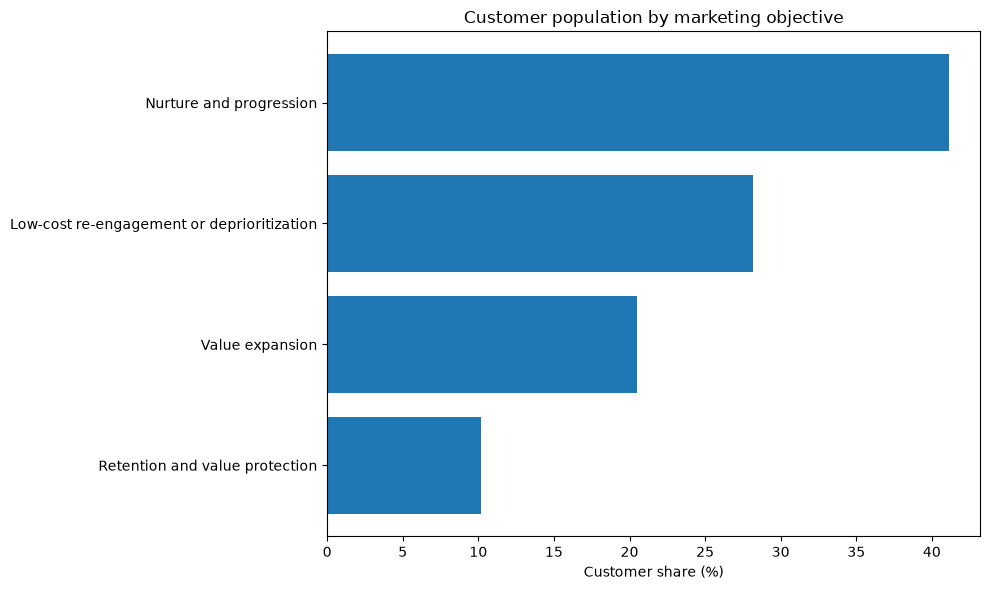

,proposed_segment_name,marketing_objective,primary_kpi,secondary_kpi,risk_note
2,Active Developing,Nurture and progression,Repeat purchase rate,Frequency / category breadth growth,This is a transitional segment and should be r...
0,Dormant Low-Value,Low-cost re-engagement or deprioritization,Reactivation rate,Incremental revenue per contacted customer,Avoid high spend on a low-response segment wit...
3,Frequent Core,Value expansion,Spend per purchase day,Category breadth / average item price,Do not push premium products when price behavi...
1,High-Value Loyal,Retention and value protection,Repeat purchase rate / retention rate,Category breadth / spend per active customer,Over-discounting high-value customers can dest...


In [11]:
objective_summary = (
    batch.groupby("marketing_objective", dropna=False)
    .agg(
        customers=("customer_id", "size"),
        observed_spend=("monetary_total_spend", "sum")
    )
    .reset_index()
)

objective_summary["pct_customers"] = objective_summary["customers"] / objective_summary["customers"].sum() * 100
objective_summary["pct_observed_spend"] = objective_summary["observed_spend"] / objective_summary["observed_spend"].sum() * 100

display(objective_summary)
objective_summary.to_csv(TABLE_DIR / "03_marketing_objective_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
plot_df = objective_summary.sort_values("pct_customers")
ax.barh(plot_df["marketing_objective"].fillna("UNKNOWN"), plot_df["pct_customers"])
ax.set_xlabel("Customer share (%)")
ax.set_title("Customer population by marketing objective")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_marketing_objective_customer_share.png", dpi=160, bbox_inches="tight")
plt.show()

kpi_framework = (
    segment_strategy[[
        "proposed_segment_name",
        "marketing_objective",
        "primary_kpi",
        "secondary_kpi",
        "risk_note"
    ]]
    .drop_duplicates()
    .sort_values("proposed_segment_name")
)

display(kpi_framework)
kpi_framework.to_csv(TABLE_DIR / "04_segment_kpi_framework.csv", index=False)

# I. Decision-Support Guardrails

In [12]:
guardrails = pd.DataFrame([
    ["No cluster-ID policy", "Actions must reference segment/profile, never technical cluster number."],
    ["No causal optimality claim", "Historical segmentation does not prove an action maximizes incremental outcome."],
    ["No fixed discount level", "Discount magnitude requires experiment, margin constraints, and response data."],
    ["Limited-history caution", "Recent/new customers have weak preference evidence."],
    ["Profile-only variables", "Age/membership variables must not be described as drivers unless used by the model."],
    ["Cross-sell is a candidate", "Segment-popular unbought category is a hypothesis, not a best-next-product prediction."],
    ["Model drift", "Review segment profiles and strategy mapping after retraining or major behavior shifts."],
    ["Campaign evaluation", "Use controlled experiments or causal methods before claiming treatment effectiveness."]
], columns=["guardrail", "rule"])

display(guardrails)
guardrails.to_csv(TABLE_DIR / "05_decision_support_guardrails.csv", index=False)

,guardrail,rule
0,No cluster-ID policy,"Actions must reference segment/profile, never ..."
1,No causal optimality claim,Historical segmentation does not prove an acti...
2,No fixed discount level,"Discount magnitude requires experiment, margin..."
3,Limited-history caution,Recent/new customers have weak preference evid...
4,Profile-only variables,Age/membership variables must not be described...
5,Cross-sell is a candidate,Segment-popular unbought category is a hypothe...
6,Model drift,Review segment profiles and strategy mapping a...
7,Campaign evaluation,Use controlled experiments or causal methods b...


# J. Report-Ready Strategy Matrix

In [13]:
strategy_matrix = (
    segment_strategy[[
        "proposed_segment_name",
        "segment_descriptor",
        "business_diagnosis",
        "marketing_objective",
        "primary_action_family",
        "secondary_action_family",
        "message_direction",
        "primary_kpi",
        "secondary_kpi",
        "risk_note",
        "interpretable_for_phase8"
    ]]
    .sort_values("proposed_segment_name")
)

display(strategy_matrix)
strategy_matrix.to_csv(TABLE_DIR / "06_report_marketing_strategy_matrix.csv", index=False)

,proposed_segment_name,segment_descriptor,business_diagnosis,marketing_objective,primary_action_family,secondary_action_family,message_direction,primary_kpi,secondary_kpi,risk_note,interpretable_for_phase8
2,Active Developing,No strong extended descriptor,Currently active customers who have not yet re...,Nurture and progression,Relevant product/category discovery,Cross-sell / repeat-purchase activation,Use known fashion preferences without aggressi...,Repeat purchase rate,Frequency / category breadth growth,This is a transitional segment and should be r...,True
0,Dormant Low-Value,No strong extended descriptor,Low historical value/frequency with low recent...,Low-cost re-engagement or deprioritization,Low-cost broad re-engagement,Experimental value proposition,Use low-cost channels before expensive incenti...,Reactivation rate,Incremental revenue per contacted customer,Avoid high spend on a low-response segment wit...,True
3,Frequent Core,Broad Fashion Interest,Strong purchase frequency but not yet exceptio...,Value expansion,Cross-sell / basket expansion,Premium-category discovery,Build on existing shopping habit with adjacent...,Spend per purchase day,Category breadth / average item price,Do not push premium products when price behavi...,True
1,High-Value Loyal,Broad Fashion Interest,Active customers with strong historical freque...,Retention and value protection,Loyalty / exclusivity / early-access engagement,Cross-sell into adjacent fashion categories,"Recognition, exclusivity, relevance; avoid unn...",Repeat purchase rate / retention rate,Category breadth / spend per active customer,Over-discounting high-value customers can dest...,True


# K. Validation

In [14]:
assert len(batch) == len(segments)
assert batch["customer_id"].duplicated().sum() == 0
assert batch["marketing_objective"].isna().sum() == 0
assert batch["primary_action_family"].isna().sum() == 0

assert (RESULT_DIR / "segment_marketing_strategy.csv").exists()
assert (RESULT_DIR / "segment_fashion_preferences.csv").exists()
assert BATCH_PATH.exists()
assert (TABLE_DIR / "06_report_marketing_strategy_matrix.csv").exists()

print("Phase 8 validation: PASSED")

Phase 8 validation: PASSED


# Report-ready conclusion template

> Kết quả phân khúc được chuyển thành một tầng Marketing Decision Support thay vì ánh xạ trực tiếp cluster ID sang hành động. Mỗi segment được mô tả bằng business diagnosis, marketing objective, action family và KPI phù hợp với behavioral profile đo được ở Phase 7.
>
> Ở cấp customer, hệ thống kết hợp segment-level strategy với lịch sử riêng của khách hàng, gồm favorite product type, garment group, price behavior, channel tendency và purchase history. Một cross-sell category candidate được tạo từ các garment group phổ biến trong segment nhưng customer chưa từng mua.
>
> Do H&M dataset không chứa campaign exposure, treatment assignment hoặc marketing response, hệ thống không khẳng định recommendation là hành động tối ưu về mặt nhân quả. Các chiến lược cần được kiểm chứng bằng A/B testing, uplift modelling hoặc causal inference trước khi triển khai như automated marketing policy.

## Khi thầy hỏi "nhập một user thì hệ thống làm gì?"

```text
customer_id
    ↓
lookup final segment
    ↓
segment strategy
    ↓
query purchase history
    ↓
favorite garment/product type
    ↓
price + channel behavior
    ↓
segment-popular category customer has not bought
    ↓
Decision Support Result
```

## Phase 9 tiếp theo

**Final Evaluation, Conclusions & Report Asset Export**

1. Tổng hợp Phase 1–8.
2. Research Question → Evidence → Conclusion.
3. RFM baseline vs Extended feature set.
4. K-Means vs GMM.
5. Final segment profiles.
6. Marketing strategy matrix.
7. Limitations.
8. Reproducibility.
9. Export final tables/figures.
10. Final findings cho báo cáo BTL.